# 04 - Data Visualizer & Editor: Statistik Deskriptif, Grafik & Visual Poster  (Tahap 1 & 4)

**Peran:** Data Visualizer & Editor - *visualisasi grafik, laporan teknis & poster infografis*
**Dikerjakan oleh:** _Salman Alfarisy Isnurdian_257006111031

### Cerita singkat tugasmu
Angka yang benar tapi tidak bisa "dibaca sekilas" = pesan tidak sampai. Kamu mengubah tabel jadi **gambar yang langsung menjelaskan**.
Selain notebook ini, kamu juga akan memegang **tata letak laporan PDF & poster A2/16:9** (dikerjakan di akhir; panduan ada di `docs/peran/PERAN_5_Data_Visualizer_Editor.md`).

| Bagian | Isi | Panduan dosen | Kapan |
|---|---|---|---|
| A | Tabel statistika deskriptif (Mean, Median, Modus, Std, Varians, IQR, Skewness) | Tahap 1d | Tahap 1 |
| B | Minimal 3 grafik: Histogram, Boxplot, Grouped Bar Chart | Tahap 1d | Tahap 1 |
| C | Scatter plot + garis tren | Tahap 4a | Tahap 4 |
| D | Grafik "siap poster" (font besar, ada pesan utama) | Poster | Tahap 4 |

> Boxplot sebelum/sesudah outlier dibuat oleh **Data Engineer** (jangan diulang; cukup dipakai).
> ⚠️ Pakai data bersih resmi. Kalau muncul peringatan DRAF SEMENTARA, jalankan ulang semuanya setelah data resmi masuk.

### 5 aturan grafik yang bagus (cek tiap grafikmu)
1. **Judul = pesan**, bukan sekadar nama variabel (mis. "PM2.5 di Pusat Kota 25 poin lebih tinggi dari Pinggiran").
2. **Sumbu berlabel + satuan.**
3. **Warna konsisten** di seluruh laporan (sudah disiapkan di `WARNA_STATUS` & `WARNA_ZONA`).
4. **Tidak ada yang berlebihan** (hilangkan garis/efek yang tidak perlu).
5. **Bisa dibaca dari jarak 1-2 meter** (untuk poster).

In [1]:
# ============ SETUP (jalankan sel ini PERTAMA) ============
# Satu-satunya yang boleh diubah: GITHUB_USER dan GITHUB_REPO (diisi sekali oleh Project Lead).
import os, sys, subprocess
GITHUB_USER = "Tur-ai"      # <- username GitHub pemilik repo
GITHUB_REPO = "udara-mobilitas-statsprob"     # <- nama repository
BRANCH = "main"

if "google.colab" in sys.modules:                      # kalau dijalankan di Google Colab
    PROYEK = "/content/proyek"
    if not os.path.exists(PROYEK):
        token = ""
        try:                                           # opsional: untuk repo PRIVATE (lihat docs/02_...)
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN") + "@"
        except Exception:
            pass
        url = f"https://{token}github.com/{GITHUB_USER}/{GITHUB_REPO}.git"
        r = subprocess.run(["git", "clone", "--depth", "1", "-b", BRANCH, url, PROYEK],
                           capture_output=True, text=True)
        if r.returncode != 0:
            pesan = (r.stderr or "").replace(token.rstrip("@"), "***") if token else (r.stderr or "")
            raise RuntimeError("Gagal clone repo. Cek GITHUB_USER/GITHUB_REPO, atau lihat bagian "
                               "'Troubleshooting' di docs/02_panduan_github_colab.md\n" + pesan)
    else:
        subprocess.run(["git", "-C", PROYEK, "pull"], capture_output=True)   # ambil update terbaru
    os.chdir(PROYEK)
elif os.path.basename(os.getcwd()) == "notebooks":    # kalau dijalankan di Jupyter lokal
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from src.helpers import *
sns.set_theme(style="whitegrid", font_scale=1.0)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Setup selesai. Folder kerja:", os.getcwd())

Setup selesai. Folder kerja: d:\Kuliah\Semester 3\StatsProb\udara-mobilitas-statsprob


In [2]:
df = muat_data_bersih()
N = len(df)
df.head()

Sumber data : DATA BERSIH RESMI (dari Data Engineer)
Jumlah baris: 345 | Jumlah kolom: 9


,ID_Observasi,Zona_Lokasi,Jenis_Hari,Jam_Sibuk,Volume_Kendaraan,Kecepatan_Angin_KmJ,Suhu_Celcius,Indeks_PM25,Status_Udara
0,OBS-12-0001,Pusat Kota,Hari Kerja,Tidak,623,24.25,27.7,35.8,Sedang
1,OBS-12-0002,Kawasan Kampus,Hari Kerja,Tidak,433,11.80,30.3,45.8,Sedang
2,OBS-12-0003,Pusat Kota,Hari Kerja,Tidak,670,16.20,25.2,54.3,Sedang
3,OBS-12-0004,Pusat Kota,Akhir Pekan,Tidak,487,3.80,27.9,51.5,Sedang
4,OBS-12-0005,Pinggiran,Hari Kerja,Tidak,273,6.60,29.6,28.8,Baik


## A. Tabel statistika deskriptif (Tahap 1d)

Ukuran-ukuran yang diminta dosen:

| Ukuran | Arti | Kegunaan |
|---|---|---|
| **Mean** | rata-rata | pusat data (sensitif outlier) |
| **Median** | nilai tengah | pusat data (tahan outlier) |
| **Modus** | nilai yang paling sering muncul | |
| **Standar deviasi** | seberapa jauh data menyebar dari rata-rata | |
| **Varians** | standar deviasi dikuadratkan | |
| **IQR** | Q3 - Q1, lebar 50% data di tengah | sebaran tahan outlier |
| **Skewness** | kemiringan: 0 simetris, > 0 ekor ke kanan, < 0 ekor ke kiri | bentuk distribusi |

💡 **Jika mean ≈ median** -> distribusi kira-kira simetris. **Jika mean > median** -> miring ke kanan (ada nilai besar yang menarik mean).

In [3]:
def modus(seri):
    m = seri.mode()
    return m.iloc[0] if len(m) else np.nan      # kalau ada beberapa modus, ambil yang terkecil

baris = {}
for kol in KOLOM_NUMERIK:
    s = df[kol]
    baris[kol] = {
        "n": s.count(), "Mean": s.mean(), "Median": s.median(), "Modus": modus(s),
        "Std_Dev": s.std(), "Varians": s.var(), "IQR": s.quantile(.75) - s.quantile(.25),
        "Skewness": s.skew(), "Min": s.min(), "Maks": s.max(),
    }
deskriptif = pd.DataFrame(baris).T.round(2)
simpan_tabel(deskriptif, "01_statistik_deskriptif")
deskriptif

[tersimpan] outputs/tables/01_statistik_deskriptif.csv


,n,Mean,Median,Modus,Std_Dev,Varians,IQR,Skewness,Min,Maks
Volume_Kendaraan,345.0,408.04,403.0,50.00,163.90,26862.12,240.0,0.02,50.00,813.00
Kecepatan_Angin_KmJ,345.0,9.84,8.8,24.25,5.91,34.97,7.4,0.87,1.00,24.25
Suhu_Celcius,345.0,28.67,28.6,27.70,2.42,5.87,3.3,0.12,22.18,35.17
Indeks_PM25,345.0,41.85,42.9,5.00,16.03,256.93,24.1,-0.07,5.00,77.90


⚠️ **Hati-hati membaca kolom Modus untuk variabel kontinu (angka berkoma / rentang lebar):**
- `Volume_Kendaraan` punya **banyak nilai modus kembar** (12 nilai muncul sama sering). Kode hanya menampilkan yang terkecil (50), jadi angka itu **tidak bisa dibaca sebagai "nilai paling umum"**. Tulis di laporan: *"tidak ada modus yang informatif (multimodal)"*.
- `Indeks_PM25` modus 5.0 muncul 5 kali: tampaknya ada **batas bawah pengukuran** di 5.0 (banyak titik "menumpuk" di sana). Jelaskan sebagai batas alat/sensor, bukan "nilai paling umum".
- `Kecepatan_Angin_KmJ` modus 24.25 muncul karena **winsorizing** oleh Data Engineer (15 nilai ekstrem dipotong ke batas atas 24.25).
Modus paling bermakna untuk variabel **kategori** (lihat tabel frekuensi di bawah).

In [4]:
# Variabel kategori: frekuensi & persentase
freq = []
for kol in KOLOM_KATEGORI:
    vc = df[kol].value_counts()
    for kategori, jumlah in vc.items():
        freq.append([kol, kategori, jumlah, round(jumlah / N * 100, 1)])
frekuensi = pd.DataFrame(freq, columns=["Variabel", "Kategori", "Frekuensi", "Persen"])
simpan_tabel(frekuensi, "01_frekuensi_kategori", index=False)
frekuensi

[tersimpan] outputs/tables/01_frekuensi_kategori.csv


,Variabel,Kategori,Frekuensi,Persen
0,Zona_Lokasi,Pusat Kota,136,39.4
1,Zona_Lokasi,Kawasan Kampus,130,37.7
2,Zona_Lokasi,Pinggiran,79,22.9
3,Jenis_Hari,Hari Kerja,229,66.4
4,Jenis_Hari,Akhir Pekan,116,33.6
5,Jam_Sibuk,Tidak,207,60.0
6,Jam_Sibuk,Ya,138,40.0
7,Status_Udara,Sedang,192,55.7
8,Status_Udara,Baik,126,36.5
9,Status_Udara,Tidak Sehat,27,7.8


✏️ **Baca tabel deskriptif (untuk Technical Writer):**
- **Mean vs median:** hampir berimpit di `Volume_Kendaraan` (408 vs 403), `Suhu_Celcius` (28.7 vs 28.6), dan `Indeks_PM25` (41.8 vs 42.9) → ketiganya kira-kira simetris (skewness mendekati 0). Satu-satunya yang mean-nya agak jauh dari median adalah `Kecepatan_Angin_KmJ` (9.84 vs 8.80, skewness +0.87) → miring ke kanan: sebagian besar hari anginnya pelan, tapi ada beberapa hari berangin kencang yang menarik rata-rata ke atas.
- **Paling bervariasi:** satuan tiap variabel berbeda, jadi dibandingkan lewat koefisien variasi (Std/Mean): `Kecepatan_Angin` ≈ 60%, `Volume_Kendaraan` ≈ 40%, `Indeks_PM25` ≈ 38%, `Suhu` ≈ 8%. Suhu paling stabil; angin paling tidak menentu.
- **Komposisi kategori:** 55.7% pengukuran berstatus Sedang, 36.5% Baik, dan hanya 7.8% Tidak Sehat (27 dari 345). Pusat Kota 39.4% data, Kawasan Kampus 37.7%, Pinggiran 22.9%; Hari Kerja 66.4% vs Akhir Pekan 33.6%; Jam Sibuk 40.0%.
- **Modus:** tidak dipakai untuk variabel kontinu (lihat catatan ⚠️ di atas).


## B. Tiga grafik wajib (Tahap 1d)

### B1. Histogram - bentuk sebaran tiap variabel angka
Garis merah putus = mean, garis hijau = median. Kalau berimpit, distribusinya simetris.

[tersimpan] outputs/figures/01_histogram_numerik.png


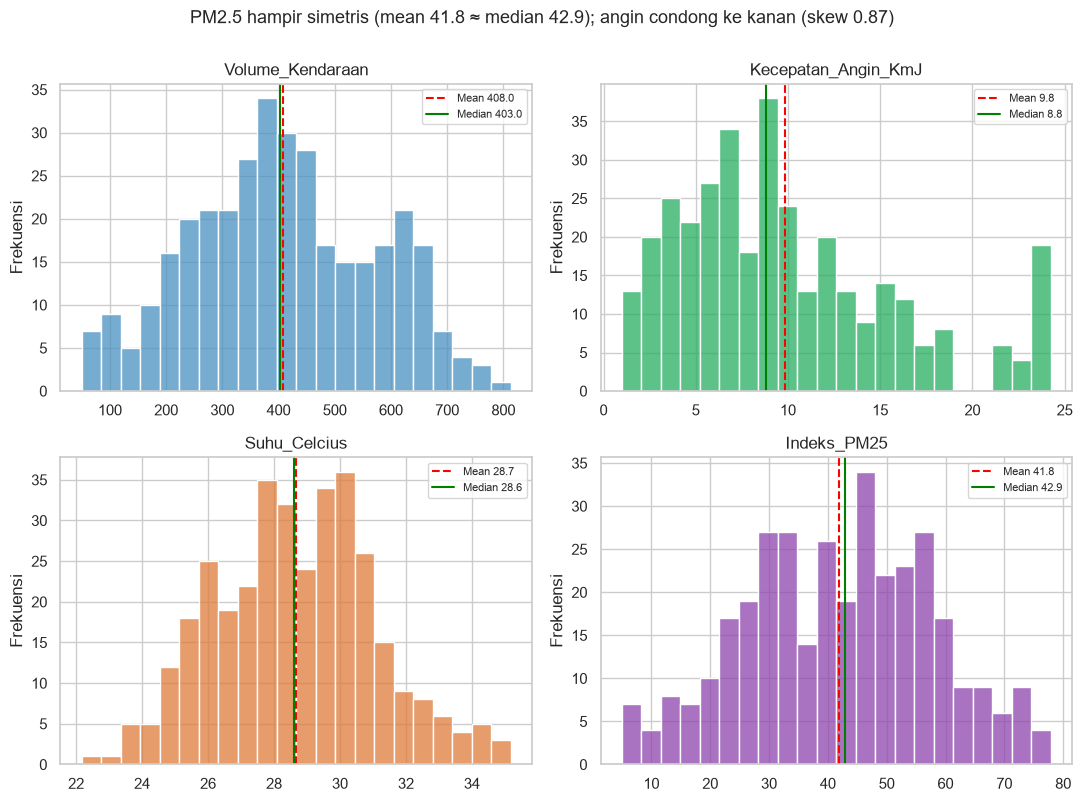

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
warna = ["#4a90c2", "#27ae60", "#e07b39", "#8e44ad"]
for ax, kol, w in zip(axes.ravel(), KOLOM_NUMERIK, warna):
    sns.histplot(df[kol], bins=22, color=w, edgecolor="white", ax=ax)
    ax.axvline(df[kol].mean(), color="red", ls="--", lw=1.5, label=f"Mean {df[kol].mean():.1f}")
    ax.axvline(df[kol].median(), color="green", ls="-", lw=1.5, label=f"Median {df[kol].median():.1f}")
    ax.set_title(kol); ax.set_xlabel(""); ax.set_ylabel("Frekuensi"); ax.legend(fontsize=8)
fig.suptitle(f"PM2.5 hampir simetris (mean {df['Indeks_PM25'].mean():.1f} ≈ median {df['Indeks_PM25'].median():.1f}); angin condong ke kanan (skew {df['Kecepatan_Angin_KmJ'].skew():.2f})", fontsize=13, y=1.0)
plt.tight_layout()
simpan_gambar(fig, "01_histogram_numerik")
plt.show()

### B2. Boxplot - bandingkan PM2.5 antar kelompok
Kotak = 50% data tengah (Q1-Q3), garis di kotak = median, kumis = jangkauan wajar, titik = outlier.

[tersimpan] outputs/figures/01_boxplot_per_kelompok.png


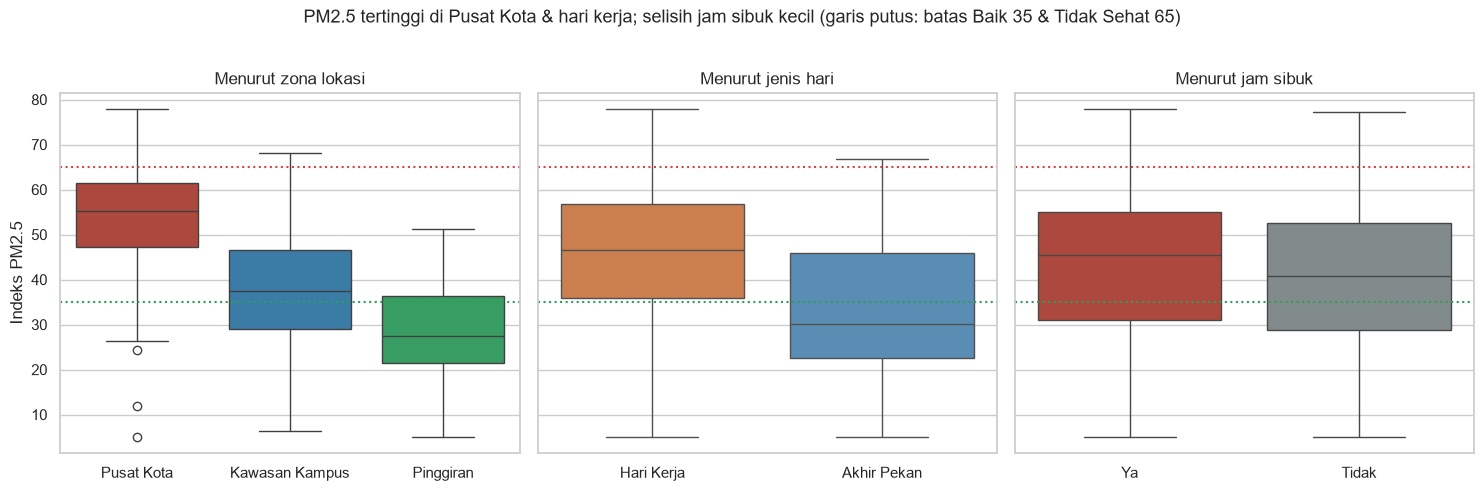

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
sns.boxplot(data=df, x="Zona_Lokasi", y="Indeks_PM25", hue="Zona_Lokasi", order=URUTAN_ZONA, palette=WARNA_ZONA, legend=False, ax=axes[0])
axes[0].set_title("Menurut zona lokasi")
sns.boxplot(data=df, x="Jenis_Hari", y="Indeks_PM25", hue="Jenis_Hari", order=["Hari Kerja", "Akhir Pekan"],
            palette={"Hari Kerja": "#e07b39", "Akhir Pekan": "#4a90c2"}, legend=False, ax=axes[1])
axes[1].set_title("Menurut jenis hari")
sns.boxplot(data=df, x="Jam_Sibuk", y="Indeks_PM25", hue="Jam_Sibuk", order=["Ya", "Tidak"],
            palette={"Ya": "#c0392b", "Tidak": "#7f8c8d"}, legend=False, ax=axes[2])
axes[2].set_title("Menurut jam sibuk")
for ax in axes:
    ax.set_xlabel(""); ax.axhline(65, ls=":", color="#d64545"); ax.axhline(35, ls=":", color="#2e9e5b")
axes[0].set_ylabel("Indeks PM2.5")
fig.suptitle("PM2.5 tertinggi di Pusat Kota & hari kerja; selisih jam sibuk kecil (garis putus: batas Baik 35 & Tidak Sehat 65)", fontsize=13, y=1.02)
plt.tight_layout()
simpan_gambar(fig, "01_boxplot_per_kelompok")
plt.show()

### B3. Grouped Bar Chart - komposisi status udara
Dua versi: **jumlah** per zona, dan **persentase** per zona (persentase lebih adil jika jumlah baris tiap zona berbeda).

[tersimpan] outputs/figures/01_grouped_bar_status_zona.png


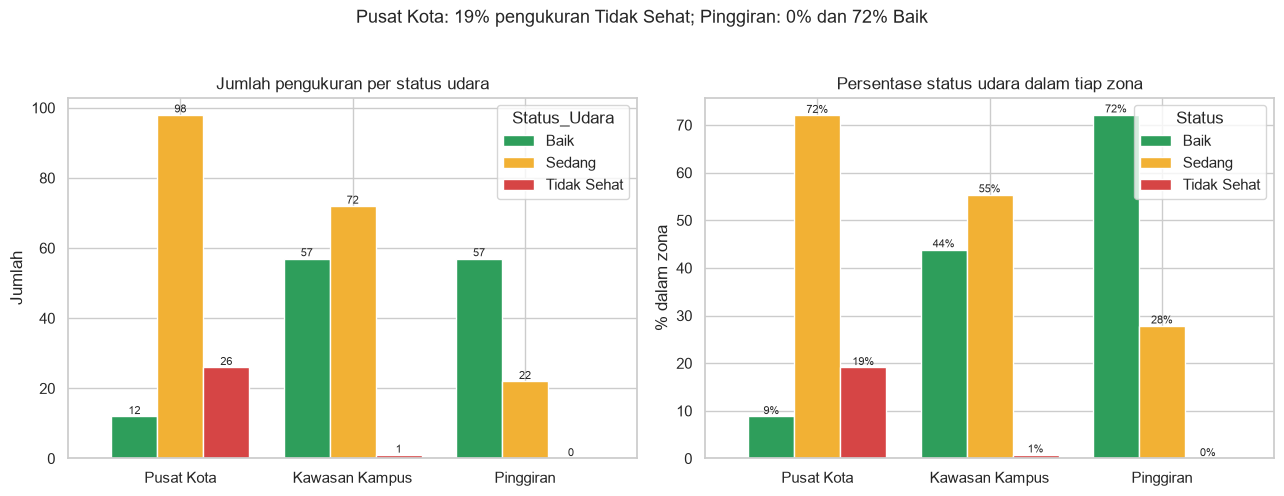

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Jumlah
hitung = pd.crosstab(df["Zona_Lokasi"], df["Status_Udara"]).reindex(URUTAN_ZONA)[URUTAN_STATUS]
hitung.plot(kind="bar", ax=axes[0], color=[WARNA_STATUS[s] for s in URUTAN_STATUS], width=0.8, rot=0, edgecolor="white")
axes[0].set_title("Jumlah pengukuran per status udara"); axes[0].set_xlabel(""); axes[0].set_ylabel("Jumlah")
for c in axes[0].containers: axes[0].bar_label(c, fontsize=8)

# Persen dalam tiap zona
persen = (hitung.div(hitung.sum(axis=1), axis=0) * 100)
persen.plot(kind="bar", ax=axes[1], color=[WARNA_STATUS[s] for s in URUTAN_STATUS], width=0.8, rot=0, edgecolor="white")
axes[1].set_title("Persentase status udara dalam tiap zona"); axes[1].set_xlabel(""); axes[1].set_ylabel("% dalam zona")
for c in axes[1].containers: axes[1].bar_label(c, fmt="%.0f%%", fontsize=8)
axes[1].legend(title="Status")
fig.suptitle("Pusat Kota: 19% pengukuran Tidak Sehat; Pinggiran: 0% dan 72% Baik", fontsize=13, y=1.03)
plt.tight_layout()
simpan_gambar(fig, "01_grouped_bar_status_zona")
plt.show()

[tersimpan] outputs/figures/01_grouped_bar_status_jamsibuk.png


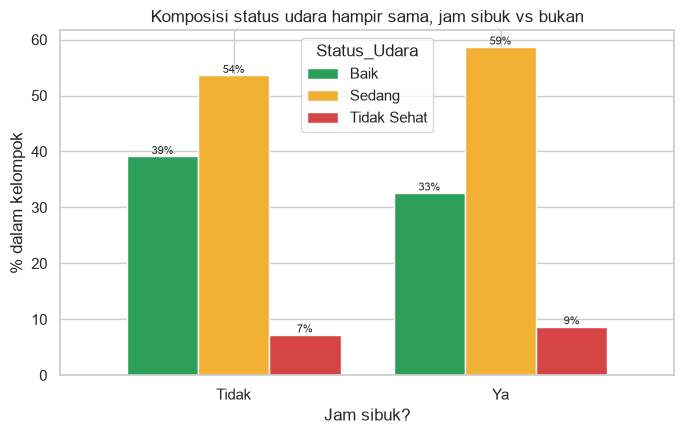

In [8]:
# Versi kedua: status udara menurut Jam Sibuk (kaitkan dengan uji Chi-Square)
hitung2 = pd.crosstab(df["Jam_Sibuk"], df["Status_Udara"])[URUTAN_STATUS]
persen2 = hitung2.div(hitung2.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(7, 4.5))
persen2.plot(kind="bar", ax=ax, color=[WARNA_STATUS[s] for s in URUTAN_STATUS], width=0.8, rot=0, edgecolor="white")
ax.set_title("Komposisi status udara hampir sama, jam sibuk vs bukan"); ax.set_xlabel("Jam sibuk?"); ax.set_ylabel("% dalam kelompok")
for c in ax.containers: ax.bar_label(c, fmt="%.0f%%", fontsize=8)
plt.tight_layout()
simpan_gambar(fig, "01_grouped_bar_status_jamsibuk")
plt.show()

✏️ **Satu kalimat "pesan utama" untuk tiap grafik** (dipakai sebagai judul/caption di laporan & poster):
- **Histogram:** Indeks PM2.5 menyebar hampir simetris di sekitar 42 (mean 41.8 ≈ median 42.9), sedangkan kecepatan angin condong ke kanan.
- **Boxplot:** PM2.5 paling tinggi di Pusat Kota dan pada hari kerja; perbedaan antara jam sibuk dan bukan jam sibuk jauh lebih kecil.
- **Grouped bar:** Pusat Kota menyumbang 26 dari 27 kejadian Tidak Sehat (19% pengukurannya), sedangkan Pinggiran tidak pernah Tidak Sehat dan 72% Baik.
- **Grouped bar (jam sibuk):** komposisi status udara saat jam sibuk dan di luar jam sibuk hampir sama (Tidak Sehat 8.7% vs 7.2%), sejalan dengan perlunya uji Chi-Square sebelum menyimpulkan ada kaitan.
- **Scatter:** makin banyak kendaraan, makin tinggi PM2.5 (r = +0.81); angin yang lebih kencang menurunkan PM2.5 (r = −0.32); suhu praktis tidak berpengaruh (r = −0.10, p = 0.064).

## C. Scatter plot dengan garis tren (Tahap 4a)

Tiap titik = 1 pengukuran. **Garis tren** = garis regresi sederhana; kemiringannya menunjukkan arah hubungan. Nilai **r** (korelasi) dicantumkan.
Tunggu/koordinasikan dengan Regression Analyst agar angka r sama dengan di tabelnya.

[tersimpan] outputs/figures/04_scatter_tren.png


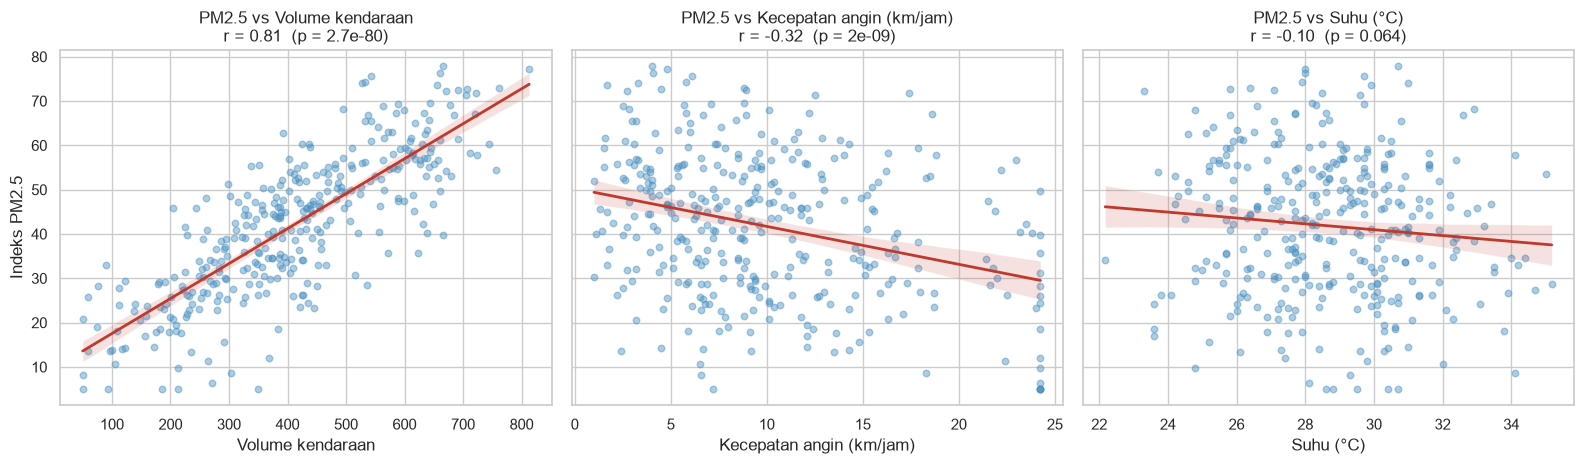

In [9]:
pasangan = [("Volume_Kendaraan", "Volume kendaraan"), ("Kecepatan_Angin_KmJ", "Kecepatan angin (km/jam)"), ("Suhu_Celcius", "Suhu (°C)")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, (kol, label) in zip(axes, pasangan):
    r, p = stats.pearsonr(df[kol], df["Indeks_PM25"])
    sns.regplot(data=df, x=kol, y="Indeks_PM25", ax=ax, scatter_kws={"alpha": .45, "s": 22, "color": "#4a90c2"},
                line_kws={"color": "#c0392b", "lw": 2})
    ax.set_title(f"PM2.5 vs {label}\nr = {r:.2f}  (p = {p:.2g})"); ax.set_xlabel(label); ax.set_ylabel("")
axes[0].set_ylabel("Indeks PM2.5")
plt.tight_layout()
simpan_gambar(fig, "04_scatter_tren")
plt.show()

[tersimpan] outputs/figures/04_scatter_volume_per_zona.png


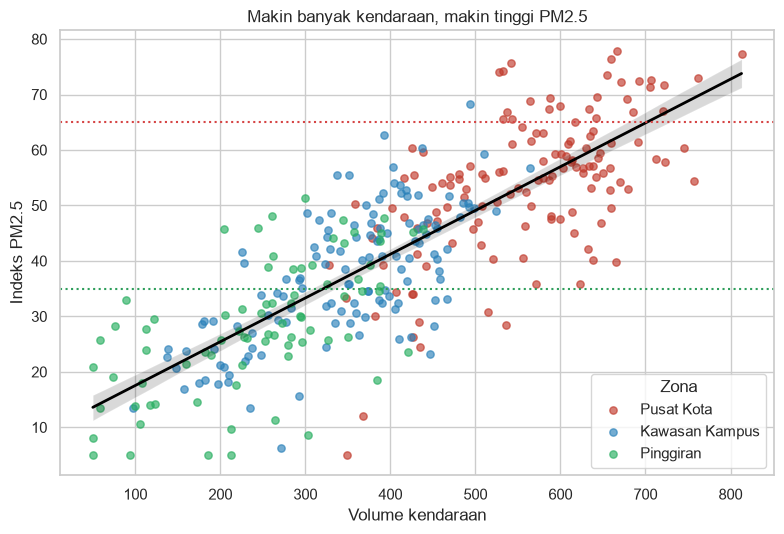

In [10]:
# Scatter utama (variabel regresi) dengan warna per zona -> menunjukkan 'cerita' tambahan
fig, ax = plt.subplots(figsize=(8, 5.5))
for z in URUTAN_ZONA:
    d = df[df["Zona_Lokasi"] == z]
    ax.scatter(d["Volume_Kendaraan"], d["Indeks_PM25"], s=28, alpha=.65, color=WARNA_ZONA[z], label=z)
sns.regplot(data=df, x="Volume_Kendaraan", y="Indeks_PM25", scatter=False, ax=ax, line_kws={"color": "black", "lw": 2})
ax.axhline(65, ls=":", color="#d64545"); ax.axhline(35, ls=":", color="#2e9e5b")
ax.set_xlabel("Volume kendaraan"); ax.set_ylabel("Indeks PM2.5")
ax.set_title("Makin banyak kendaraan, makin tinggi PM2.5"); ax.legend(title="Zona")
plt.tight_layout()
simpan_gambar(fig, "04_scatter_volume_per_zona")
plt.show()

## D. Grafik "siap poster" (font besar, 1 pesan per grafik)

Poster dilihat dari jauh, jadi: **font >= 14 pt, garis tebal, sedikit elemen**. Ukuran 16:9 cocok ditempel di slide/poster.
Tiga grafik di bawah mewakili 3 temuan utama (angka disesuaikan otomatis dari data). **Ubah judulnya** jika temuan tim berbeda.

[tersimpan] outputs/figures/04_poster_pm25_per_zona.png


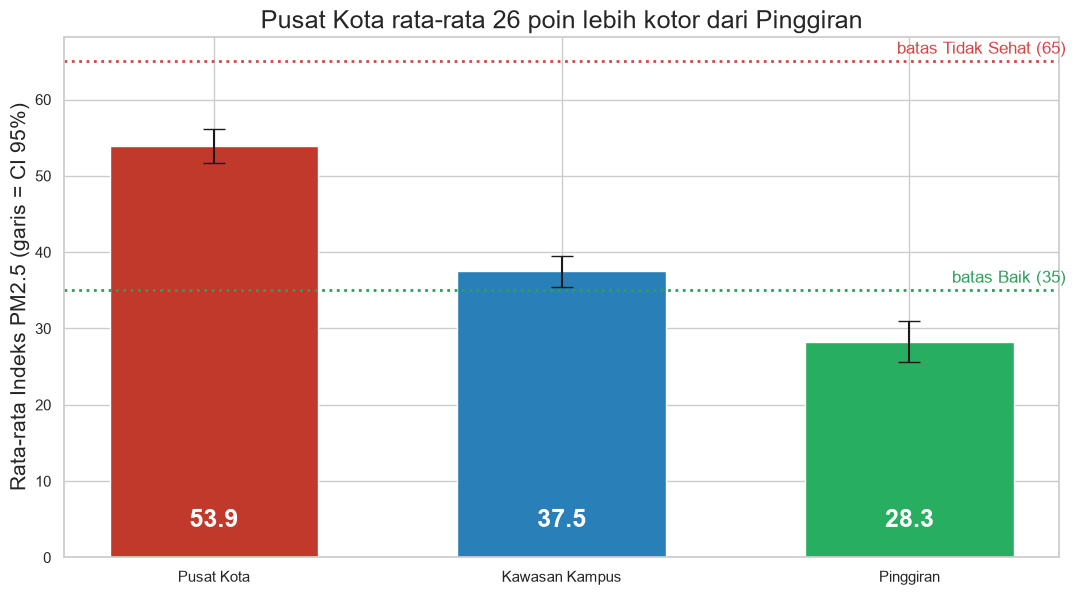

In [11]:
plt.rcParams.update({"font.size": 15, "axes.titlesize": 18, "axes.labelsize": 15})

# --- Poster 1: rata-rata PM2.5 per zona + CI 95% ---
ringkas = df.groupby("Zona_Lokasi")["Indeks_PM25"].agg(["mean", "std", "count"]).loc[URUTAN_ZONA]
ringkas["ci"] = stats.t.ppf(0.975, ringkas["count"] - 1) * ringkas["std"] / np.sqrt(ringkas["count"])
fig, ax = plt.subplots(figsize=(11, 6.2))
bars = ax.bar(ringkas.index, ringkas["mean"], yerr=ringkas["ci"], capsize=8,
              color=[WARNA_ZONA[z] for z in ringkas.index], edgecolor="white", width=0.6)
for b_, m in zip(bars, ringkas["mean"]):
    ax.text(b_.get_x() + b_.get_width() / 2, 4, f"{m:.1f}", ha="center", color="white", fontsize=18, fontweight="bold")
ax.axhline(35, ls=":", color="#2e9e5b", lw=2); ax.text(2.45, 36, "batas Baik (35)", ha="right", color="#2e9e5b", fontsize=12)
ax.axhline(65, ls=":", color="#d64545", lw=2); ax.text(2.45, 66, "batas Tidak Sehat (65)", ha="right", color="#d64545", fontsize=12)
sel = ringkas["mean"].max() - ringkas["mean"].min()
ax.set_title(f"Pusat Kota rata-rata {ringkas['mean'].max() - ringkas.loc['Pinggiran','mean']:.0f} poin lebih kotor dari Pinggiran")
ax.set_ylabel("Rata-rata Indeks PM2.5 (garis = CI 95%)"); ax.set_xlabel("")
plt.tight_layout()
simpan_gambar(fig, "04_poster_pm25_per_zona")
plt.show()

[tersimpan] outputs/figures/04_poster_hari_kerja_vs_akhir_pekan.png


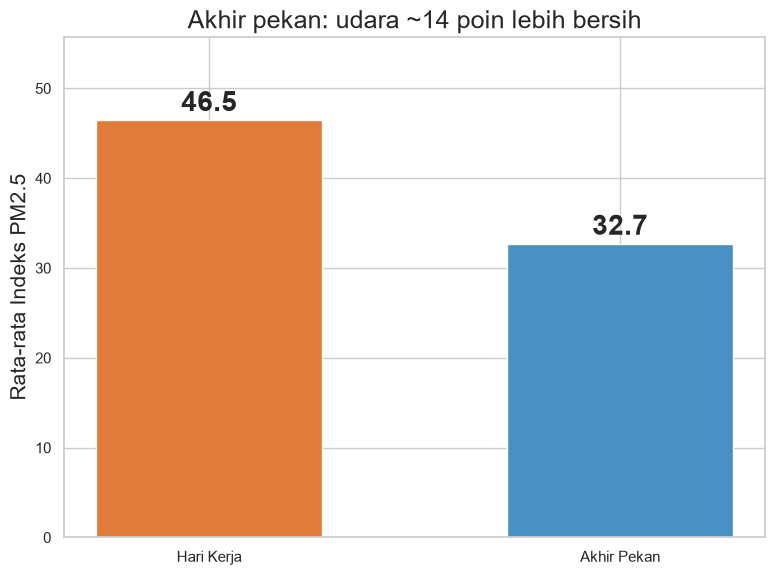

[tersimpan] outputs/figures/04_poster_tidak_sehat_per_zona.png


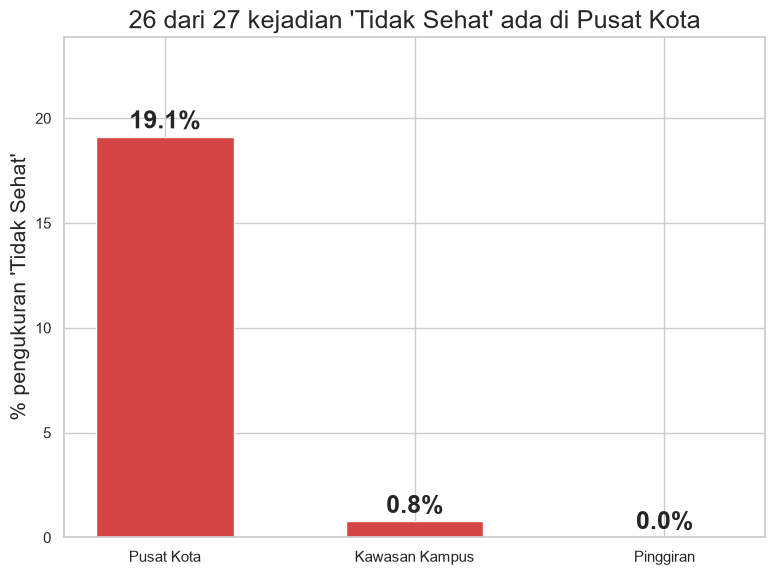

In [12]:
# --- Poster 2: Hari kerja vs akhir pekan ---
rata = df.groupby("Jenis_Hari")["Indeks_PM25"].mean()
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(["Hari Kerja", "Akhir Pekan"], [rata["Hari Kerja"], rata["Akhir Pekan"]], color=["#e07b39", "#4a90c2"], width=0.55)
for i, v in enumerate([rata["Hari Kerja"], rata["Akhir Pekan"]]):
    ax.text(i, v + 1, f"{v:.1f}", ha="center", fontsize=20, fontweight="bold")
ax.set_ylim(0, max(rata) * 1.2)
ax.set_title(f"Akhir pekan: udara ~{rata['Hari Kerja'] - rata['Akhir Pekan']:.0f} poin lebih bersih")
ax.set_ylabel("Rata-rata Indeks PM2.5")
plt.tight_layout()
simpan_gambar(fig, "04_poster_hari_kerja_vs_akhir_pekan")
plt.show()

# --- Poster 3: proporsi 'Tidak Sehat' per zona ---
ts = (df.assign(ts=df["Status_Udara"] == "Tidak Sehat").groupby("Zona_Lokasi")["ts"].mean().loc[URUTAN_ZONA] * 100)
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(ts.index, ts.values, color="#d64545", width=0.55)
for i, v in enumerate(ts.values):
    ax.text(i, v + 0.4, f"{v:.1f}%", ha="center", fontsize=18, fontweight="bold")
ax.set_ylim(0, max(ts.max() * 1.25, 5)); ax.set_ylabel("% pengukuran 'Tidak Sehat'")
n_ts = int((df["Status_Udara"] == "Tidak Sehat").sum()); n_pk = int(((df["Status_Udara"] == "Tidak Sehat") & (df["Zona_Lokasi"] == "Pusat Kota")).sum())
ax.set_title(f"{n_pk} dari {n_ts} kejadian 'Tidak Sehat' ada di Pusat Kota")
plt.tight_layout()
simpan_gambar(fig, "04_poster_tidak_sehat_per_zona")
plt.show()
plt.rcParams.update(plt.rcParamsDefault)   # kembalikan ukuran font normal
sns.set_theme(style="whitegrid")

💡 Judul grafik poster ke-3 sudah **dicek ke angka**: dari 27 pengukuran 'Tidak Sehat', 26 ada di Pusat Kota (96%), 1 di Kawasan Kampus, 0 di Pinggiran. Kalau data bersih berubah, judul dihitung ulang otomatis.

## Serahkan hasil

In [13]:
unduh_hasil("hasil_04_visualizer")

11 file dimasukkan ke hasil_04_visualizer.zip:
  - outputs/tables/01_statistik_deskriptif.csv
  - outputs/tables/01_frekuensi_kategori.csv
  - outputs/figures/01_histogram_numerik.png
  - outputs/figures/01_boxplot_per_kelompok.png
  - outputs/figures/01_grouped_bar_status_zona.png
  - outputs/figures/01_grouped_bar_status_jamsibuk.png
  - outputs/figures/04_scatter_tren.png
  - outputs/figures/04_scatter_volume_per_zona.png
  - outputs/figures/04_poster_pm25_per_zona.png
  - outputs/figures/04_poster_hari_kerja_vs_akhir_pekan.png
  - outputs/figures/04_poster_tidak_sehat_per_zona.png
(bukan di Colab - ZIP ada di folder kerja)


'hasil_04_visualizer.zip'

### ✅ Checklist selesai
- [ ] Tabel deskriptif lengkap (Mean, Median, Modus, Std, Varians, IQR, Skewness) tersimpan
- [ ] >= 3 grafik jenis berbeda: histogram, boxplot, grouped bar chart (+ scatter di Tahap 4)
- [ ] Setiap grafik punya judul bermakna, label sumbu, warna konsisten
- [ ] Grafik poster dicek: kalimat judul sesuai angka sebenarnya
- [ ] Semua file di-upload ke `outputs/figures` & `outputs/tables`
- [ ] Aku bisa menjelaskan tanpa membaca: kenapa pilih jenis grafik ini, cara membaca boxplot, apa arti garis tren